[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch59_LabCh59_Profiling_A_Training_Run.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 59: Where the Time and Memory Go** (Part XIII: Small, Fast and Shipped).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=59](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=59)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch59 - Profiling a training run
## Find out where the time and the memory go, then fix the right thing

This lab goes with **Chapter 59** of *The Why Book of Deep Learning, Part 2*.

You are handed a training script that is slower than it should be. A small CNN learns CIFAR-10 from images
stored as compressed files, and somebody wrote the input pipeline as a plain Python loop. Your job is not to
guess what is slow. Your job is to **measure**, fix the slowest part, and measure again.

| Part | Question | Steps |
|---|---|---|
| One: time | Is the data or the model the slow half? What does each fix buy? | 4 to 13 |
| Two: memory | Which numbers fill the memory during training, and how do you train a bigger batch than fits? | 14 to 18 |
| Three: the goal | Is the fastest setting the one that gets you a result soonest? | 19 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Time a pipeline fairly: warm up, repeat, take the median, quote examples per second | Step 5 |
| Split one training step into data time and model time | Step 6 |
| Build a `tf.data` pipeline with `map`, `cache`, `batch`, `prefetch` in the right order | Steps 7 to 10 |
| Say why the last three fixes changed nothing end to end | Step 11 |
| Read a throughput against batch size curve | Step 12 |
| Measure `steps_per_execution` and `jit_compile` instead of trusting them | Step 13 |
| Estimate training memory by hand and check it against the model | Steps 14 and 15 |
| Prove that gradient accumulation gives the same gradient as a bigger batch, and when it does not | Steps 16 and 17 |
| Switch on mixed precision correctly and say what it needs to pay off | Step 18 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **This lab runs on a CPU, and says so.** The saved copy was run on the author's laptop CPU with no GPU.
> Every timing below is a measurement on the machine that ran it. **Your numbers will differ**, from machine
> to machine and from run to run, so read the ratios and the order of magnitude and ignore the last digits.
> Close other heavy programs before you time anything.

> **Runtime:** about three to five minutes on a laptop CPU.

> **Honest scale:** this is a miniature: 8,000 small images and a model of about 291 thousand parameters. On a
> CPU the model is slow, so a mildly clumsy pipeline is enough to hold it back. On a GPU the same model would
> ask for images many times faster, and the pipeline would matter far more than it does here. The method is the
> same at any size: time the parts, fix the slowest, time again.

---
## Step 1 - Imports, one seed, and what hardware we have

In [1]:
import os, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore", message="Your input ran out of data")   # we time short runs on purpose
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 59
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True, linewidth=120)
t_start = time.time()

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs visible to TensorFlow:", len(gpus), "| CPU cores reported:", os.cpu_count())
print("Everything below runs on the", "GPU" if gpus else "CPU", "of this machine.")

TensorFlow 2.21.0 | Keras 3.14.1
GPUs visible to TensorFlow: 0 | CPU cores reported: 12
Everything below runs on the CPU of this machine.


---
## Step 2 - The data, stored the way real data is stored

`keras.datasets.cifar10` hands you a tidy array that is already decoded. Real projects do not start there.
They start with a folder of compressed image files, and every image has to be **decoded** before the model
can see it. To keep that cost in the lab without downloading anything, we take 10,000 CIFAR-10 images and
compress each one to **PNG bytes in memory**, as if we had read them from a disk.

- 8,000 images for training, 2,000 for validation.
- `png_train[i]` is a Python `bytes` object: one compressed file.

> **Predict:** a raw CIFAR-10 image is 32 x 32 x 3 = 3,072 bytes. PNG compression is lossless. Will the
> average PNG be much smaller than 3,072 bytes, about the same, or larger?

In [2]:
N_TRAIN, N_VAL, BATCH = 8000, 2000, 64
(x_all, y_all), _ = keras.datasets.cifar10.load_data()
x_raw, y_raw = x_all[:N_TRAIN + N_VAL], y_all[:N_TRAIN + N_VAL, 0].astype("int32")

png_all = [tf.io.encode_png(img).numpy() for img in x_raw]          # one compressed "file" per image
png_train, y_train = png_all[:N_TRAIN], y_raw[:N_TRAIN]
png_val, y_val = png_all[N_TRAIN:], y_raw[N_TRAIN:]
x_val = x_raw[N_TRAIN:].astype("float32") / 255.0                    # validation set, decoded once

print("raw image:", x_raw[0].shape, x_raw[0].dtype, "=", x_raw[0].nbytes, "bytes")
print("training files:", len(png_train), "| validation files:", len(png_val))
print("average PNG size: %.0f bytes" % np.mean([len(p) for p in png_train]))
print("class counts in the training subset:", np.bincount(y_train))

raw image: (32, 32, 3) uint8 = 3072 bytes
training files: 8000 | validation files: 2000
average PNG size: 2254 bytes
class counts in the training subset: [796 765 817 809 806 765 832 809 809 792]


### Why we see this

A 32 x 32 photograph has little repetition for a lossless compressor to remove, so the files are only a
little smaller than the raw pixels. That does not matter here. What matters is that every image now has to
pass through a decoder before training, as it does in a real project.

---
## Step 3 - The model, with its parameters counted by hand

A small CNN in the style of Chapter 16: three convolutions, two poolings, one hidden Dense layer.

The counting rules are Chapter 14's: a convolution has `(k * k * channels_in + 1) * filters` parameters,
a Dense layer has `(inputs + 1) * units`, pooling and Flatten have none.

> **Predict:** which single layer holds most of the parameters? Write down its name before you run the cell.

In [3]:
def build_cnn(name="cnn"):
    return keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(name="pool1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv3"),
        layers.MaxPooling2D(name="pool2"),
        layers.Flatten(name="flatten"),
        layers.Dense(64, activation="relu", name="dense"),
        layers.Dense(10, name="logits"),
    ], name=name)

def compiled(model, lr=1e-3, **kw):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"], **kw)
    return model

hand = {
    "conv1": (3 * 3 * 3 + 1) * 32,
    "conv2": (3 * 3 * 32 + 1) * 32,
    "conv3": (3 * 3 * 32 + 1) * 64,
    "dense": (8 * 8 * 64 + 1) * 64,
    "logits": (64 + 1) * 10,
}
P = sum(hand.values())
model = compiled(build_cnn())
for name, n in hand.items():
    assert model.get_layer(name).count_params() == n
    print(f"{name:7s} {n:>9,}   ({100 * n / P:4.1f}% of the model)")
assert model.count_params() == P == 291_498
print(f"total   {P:>9,}   parameters, counted by hand and confirmed by Keras")

conv1         896   ( 0.3% of the model)
conv2       9,248   ( 3.2% of the model)
conv3      18,496   ( 6.3% of the model)
dense     262,208   (90.0% of the model)
logits        650   ( 0.2% of the model)
total     291,498   parameters, counted by hand and confirmed by Keras


### Why we see this

The Dense layer after Flatten holds about nine tenths of the parameters, the pattern Chapter 14 pointed out.
Keep that in mind for Step 14: the layers that hold the parameters are not the layers that fill the memory.

---
## Step 4 - The clumsy input pipeline

Here is the pipeline as somebody first wrote it. Nothing in it is wrong. It gives correct batches. It is
written one image at a time in Python:

1. decode one PNG,
2. scale it to 0..1,
3. augment it (Chapter 11): pad by 4 pixels and take a random 32 x 32 crop, flip it left to right half the
   time, shift its brightness a little,
4. `yield` it, and let `tf.data` collect 64 of them into a batch.

> **Predict:** the model trains on about three thousand images a second on a laptop CPU (you will measure
> it in Step 6). Will this pipeline supply images faster or slower than that?

In [4]:
def clumsy_one(i):
    img = tf.io.decode_png(png_train[i]).numpy().astype("float32") / 255.0   # decode one file
    img = np.pad(img, ((4, 4), (4, 4), (0, 0)), mode="reflect")              # pad to 40 x 40
    oy, ox = rng.integers(0, 9, size=2)
    img = img[oy:oy + 32, ox:ox + 32]                                        # random crop
    if rng.random() < 0.5:
        img = img[:, ::-1]                                                   # random flip
    img = np.clip(img + rng.uniform(-0.2, 0.2), 0.0, 1.0)                    # brightness shift
    return img, y_train[i]

def clumsy_generator():
    for i in rng.permutation(N_TRAIN):          # a new shuffle every epoch
        yield clumsy_one(i)

signature = (tf.TensorSpec((32, 32, 3), tf.float32), tf.TensorSpec((), tf.int32))
pipes = {}
pipes["A clumsy: Python, one image at a time"] = (
    tf.data.Dataset.from_generator(clumsy_generator, output_signature=signature).batch(BATCH))

xb, yb = next(iter(pipes["A clumsy: Python, one image at a time"]))
print("one batch:", xb.shape, xb.dtype, "| labels:", yb.shape, yb.dtype)
print("pixel range: %.2f to %.2f" % (float(tf.reduce_min(xb)), float(tf.reduce_max(xb))))

one batch: (64, 32, 32, 3) <dtype: 'float32'> | labels: (64,) <dtype: 'int32'>
pixel range: 0.00 to 1.00


---
## Step 5 - A fair stopwatch, and the first-step trap

Three rules for every timing in this lab:

1. **Warm up first.** The first step of anything in TensorFlow builds a graph, allocates memory and fills
   buffers. It is not representative, so we never time it.
2. **Repeat and take the median.** One timing is an anecdote. We take three and keep the middle one, which
   ignores a hiccup caused by another program.
3. **Quote examples per second.** Seconds per epoch depends on the dataset size, and steps per second depends
   on the batch size. Examples per second can be compared across both.

The cell defines the two stopwatches used for the rest of the lab, then shows why rule 1 exists.

> **Predict:** how many times slower is the very first training step than the second one? 2 times? 10? 100?

In [5]:
REPS = 3
median = lambda f: float(np.median([f() for _ in range(REPS)]))

def data_rate(ds, n_batches=40, warm=3):
    """Examples per second the pipeline can deliver when nothing consumes them but a loop."""
    def once():
        it = iter(ds)
        for _ in range(warm):
            next(it)
        t, count = time.perf_counter(), 0
        for _ in range(n_batches):
            count += next(it)[0].shape[0]
        return count / (time.perf_counter() - t)
    return median(once)

def fit_rate(model, ds, n_batches=40, batch=BATCH):
    """Examples per second of real training: model.fit pulling batches from the pipeline."""
    model.fit(ds.take(4), epochs=1, verbose=0)                     # warm-up, not timed
    def once():
        t = time.perf_counter()
        model.fit(ds.take(n_batches), epochs=1, verbose=0)
        return n_batches * batch / (time.perf_counter() - t)
    return median(once)

fresh = compiled(build_cnn())
t = time.perf_counter(); fresh.train_on_batch(xb, yb); first = time.perf_counter() - t
later = []
for _ in range(10):
    t = time.perf_counter(); fresh.train_on_batch(xb, yb); later.append(time.perf_counter() - t)
print("first training step : %7.1f ms   (builds the graph)" % (1000 * first))
print("a later step (median): %6.1f ms" % (1000 * np.median(later)))
print("the first step was about %.0f times slower" % (first / np.median(later)))

first training step :   897.3 ms   (builds the graph)
a later step (median):   18.3 ms
the first step was about 49 times slower


### Why we see this

The first call traces the Python code into a graph and sets everything up (Chapter 30 called this the lazy
first call). In the saved run it was tens of times slower than a normal step. A benchmark that includes it,
or that runs only a handful of steps, reports the cost of starting up, not the cost of training.

---
## Step 6 - Time the parts: data only, model only, both

This is the whole method of the chapter in one cell. We time three things:

- **data only**: pull batches from the clumsy pipeline and throw them away. No model.
- **model only**: train on one batch that is already sitting in memory, again and again. No pipeline.
- **both**: real training, the model fed by the pipeline.

> **Predict:** which is the slower half, data or model? And will "both" be nearer the slower one, or
> clearly worse than either?

In [6]:
in_memory = tf.data.Dataset.from_tensors((xb, yb)).repeat()      # one ready batch, for ever: data cost ~ 0

rate = {}
rate["data"] = data_rate(pipes["A clumsy: Python, one image at a time"], n_batches=30)
rate["model"] = fit_rate(model, in_memory)
rate["both"] = fit_rate(model, pipes["A clumsy: Python, one image at a time"], n_batches=30)

ms = {k: 1000 * BATCH / v for k, v in rate.items()}             # milliseconds per batch of 64
print(f"{'':12s}{'examples/s':>12s}{'ms per batch':>15s}")
for k in ("data", "model", "both"):
    print(f"{k + ' only' if k != 'both' else 'both':12s}{rate[k]:12,.0f}{ms[k]:15.1f}")
print("\ndata ms + model ms = %.1f ms   | measured for both = %.1f ms" % (ms["data"] + ms["model"], ms["both"]))
print("share of one step spent waiting for data: about %.0f%%" % (100 * ms["data"] / (ms["data"] + ms["model"])))

              examples/s   ms per batch
data only          2,006           31.9
model only         3,431           18.7
both               1,399           45.8

data ms + model ms = 50.6 ms   | measured for both = 45.8 ms
share of one step spent waiting for data: about 63%


### Why we see this

With this pipeline the two jobs mostly take turns: Python prepares a batch while the model waits, then the
model trains while Python waits. So the times very nearly **add**, and training runs slower than either part
alone. (In the saved run "both" came out a little under the sum, so a little of the fetching overlaps with the
model's work.) The data took the larger share of every step. Buying a faster processor for the model could not fix that:
if the model's time fell to zero, training would still run only at the "data only" speed.

---
## Step 7 - Fix 1: move the work out of Python, into `tf.data`

`Dataset.from_tensor_slices` holds the compressed files and labels. `map` applies a function to every element,
and that function is made of TensorFlow operations, so it runs as compiled code with no Python in the loop.
The steps are the same as before: decode, scale, augment, batch.

> **Predict:** the arithmetic is identical. How much faster can it be only because Python left the loop:
> 1.5 times? 5 times? 50 times?

In [7]:
def decode(png, label):
    img = tf.io.decode_png(png, channels=3)
    return tf.cast(img, tf.float32) / 255.0, label

def augment_one(img, label):                       # one image at a time, in TensorFlow ops
    img = tf.pad(img, [[4, 4], [4, 4], [0, 0]], mode="REFLECT")
    img = tf.image.random_crop(img, (32, 32, 3))
    img = tf.image.random_flip_left_right(img)
    img = tf.clip_by_value(img + tf.random.uniform((), -0.2, 0.2), 0.0, 1.0)
    return img, label

files = tf.data.Dataset.from_tensor_slices((png_train, y_train))

pipes["B tf.data: map, one image at a time"] = (
    files.shuffle(N_TRAIN).map(decode).map(augment_one).batch(BATCH).repeat())

b_rate = data_rate(pipes["B tf.data: map, one image at a time"])
print("A, clumsy Python : %8.0f examples/s" % rate["data"])
print("B, tf.data map   : %8.0f examples/s   (%.1f times A)" % (b_rate, b_rate / rate["data"]))

A, clumsy Python :     2006 examples/s
B, tf.data map   :     9929 examples/s   (5.0 times A)


### Why we see this

Nothing about the mathematics changed. What changed is who does the bookkeeping. In version A every image
crosses between Python and TensorFlow several times, and each crossing costs far more than the arithmetic on
3,072 numbers. In version B the whole chain runs inside TensorFlow's runtime.

---
## Step 8 - `cache`: do the unchanging work once, and put it in the right place

Decoding a file gives the same pixels every epoch. Augmentation must give different pixels every epoch.
`cache()` remembers everything **upstream** of it after the first pass. So it belongs **after** decode and
**before** shuffle and augmentation.

The cell builds the right order and the wrong order, then looks at the same image in two epochs.

> **Predict:** with `cache()` placed after the augmentation, what will the second epoch's version of an image
> look like compared with the first epoch's?

In [8]:
pipes["C + cache after decode"] = (
    files.map(decode).cache().shuffle(N_TRAIN).map(augment_one).batch(BATCH).repeat())
for _ in pipes["C + cache after decode"].take(N_TRAIN // BATCH + 1):
    pass                                                      # one full pass fills the cache
c_rate = data_rate(pipes["C + cache after decode"])
print("B, no cache           : %8.0f examples/s" % b_rate)
print("C, cache after decode : %8.0f examples/s   (%.2f times B)" % (c_rate, c_rate / b_rate))

# the same 64 files, no shuffling, two epochs, cache in the right place and in the wrong place
first64 = files.take(64).map(decode)
right = first64.cache().map(augment_one).batch(64).repeat(2)
wrong = first64.map(augment_one).cache().batch(64).repeat(2)
def two_epochs(ds):                                           # one iterator, two passes over the 64 files
    it = iter(ds)
    return next(it)[0].numpy(), next(it)[0].numpy()
r1, r2 = two_epochs(right)
w1, w2 = two_epochs(wrong)
print("\ncache BEFORE augmentation: epochs identical?", bool(np.array_equal(r1, r2)),
      "| mean pixel change %.3f" % np.abs(r1 - r2).mean())
print("cache AFTER  augmentation: epochs identical?", bool(np.array_equal(w1, w2)),
      "| mean pixel change %.3f" % np.abs(w1 - w2).mean())
assert not np.array_equal(r1, r2) and np.array_equal(w1, w2)

B, no cache           :     9929 examples/s
C, cache after decode :     9241 examples/s   (0.93 times B)

cache BEFORE augmentation: epochs identical? False | mean pixel change 0.190
cache AFTER  augmentation: epochs identical? True | mean pixel change 0.000


### Why we see this

Two results, and both matter.

**The speed.** In the saved run the cache changed the rate very little. That is not a failure of `cache`; it
is a fact about this data. Decoding a 32 x 32 PNG is a tiny job, so removing it saves little, and the
per-image overhead of the augmentation still dominates. With large JPEG photographs read from a disk,
decoding is usually the most expensive stage and the cache (when the decoded data fits in memory) is the
biggest single fix. **You find out which case you are in by measuring.**

**The trap.** With the cache after the augmentation, every epoch replays the first epoch's crops and flips.
The pipeline is fast, nothing warns you, and the augmentation has silently stopped working: the model sees
8,000 fixed images again and overfits as if you had never augmented.

(A detail for the careful: the check walks through two epochs with **one** iterator and `repeat(2)`. With a
global seed set, as in Step 1, a brand-new iterator over the same dataset replays the same random numbers
from the start. That is reproducibility doing its job, and one more reason to shuffle before you augment.)

---
## Step 9 - Batch first, then augment the whole batch at once

So far the augmentation runs 64 separate times per batch. Each run has a fixed overhead (calling the
function, creating small tensors) that is larger than the work itself. The cure is to **batch first** and
write the augmentation for a whole batch: one padded tensor, one crop offset per image, one flip decision
per image, one brightness shift per image.

> **Predict:** the same arithmetic on the same number of pixels, done in one call per batch. Faster or not?

In [9]:
def augment_batch(x, labels):                      # a whole batch in one go; every image still gets its own randomness
    b = tf.shape(x)[0]
    x = tf.pad(x, [[0, 0], [4, 4], [4, 4], [0, 0]], mode="REFLECT")
    oy = tf.random.uniform((b,), 0, 9, tf.int32)
    ox = tf.random.uniform((b,), 0, 9, tf.int32)
    x = tf.gather(x, oy[:, None] + tf.range(32), axis=1, batch_dims=1)       # each image's own 32 rows
    x = tf.gather(x, ox[:, None] + tf.range(32), axis=2, batch_dims=1)       # each image's own 32 columns
    flip = tf.random.uniform((b, 1, 1, 1)) < 0.5
    x = tf.where(flip, tf.reverse(x, axis=[2]), x)
    x = tf.clip_by_value(x + tf.random.uniform((b, 1, 1, 1), -0.2, 0.2), 0.0, 1.0)
    return x, labels

decoded = files.map(decode).cache()                # decoded once, kept in memory
for _ in decoded:
    pass                                           # fill the cache

pipes["D + batch, then augment the batch"] = (
    decoded.shuffle(N_TRAIN).batch(BATCH).map(augment_batch).repeat())
d_rate = data_rate(pipes["D + batch, then augment the batch"])
xb_d, _ = next(iter(pipes["D + batch, then augment the batch"]))
print("batch from D:", xb_d.shape, "| pixel range %.2f to %.2f" % (float(tf.reduce_min(xb_d)), float(tf.reduce_max(xb_d))))
print("C, augment one image at a time : %8.0f examples/s" % c_rate)
print("D, augment a batch at a time   : %8.0f examples/s   (%.1f times C)" % (d_rate, d_rate / c_rate))

batch from D: (64, 32, 32, 3) | pixel range 0.00 to 1.00
C, augment one image at a time :     9241 examples/s
D, augment a batch at a time   :    18455 examples/s   (2.0 times C)


### Why we see this

One call that handles 64 images pays the fixed overhead once, not 64 times. This is the same reason batches
exist for the model, and it is the general rule of fast numerical code: **few calls on big arrays beat many
calls on small ones**.

---
## Step 10 - Parallel calls and `prefetch`

Two last switches:

- `num_parallel_calls=tf.data.AUTOTUNE` lets `map` use several CPU cores at once.
- `prefetch(tf.data.AUTOTUNE)` prepares the next batches **in the background while the model trains** on the
  current one. It goes last in the pipeline.

> **Predict:** `prefetch` does not make any batch cheaper to produce. Where could its benefit show up:
> in "data only", or in "both"?

In [10]:
AUTO = tf.data.AUTOTUNE
pipes["E + parallel map"] = (
    decoded.shuffle(N_TRAIN).batch(BATCH).map(augment_batch, num_parallel_calls=AUTO).repeat())
pipes["F + prefetch"] = (
    decoded.shuffle(N_TRAIN).batch(BATCH).map(augment_batch, num_parallel_calls=AUTO).repeat().prefetch(AUTO))

e_rate = data_rate(pipes["E + parallel map"])
f_rate = data_rate(pipes["F + prefetch"])
print("D, one core       : %8.0f examples/s" % d_rate)
print("E, parallel map   : %8.0f examples/s   (%.1f times D)" % (e_rate, e_rate / d_rate))
print("F, plus prefetch  : %8.0f examples/s   (%.1f times E)" % (f_rate, f_rate / e_rate))

D, one core       :    18455 examples/s
E, parallel map   :    86145 examples/s   (4.7 times D)
F, plus prefetch  :    94614 examples/s   (1.1 times E)


---
## Step 11 - The scoreboard: what each fix bought, end to end

"Data only" speed is not what you care about. Training speed is. So we now run real training with each of the
six pipelines and put the two columns side by side, with the model-only speed from Step 6 as the ceiling.

> **Predict:** from A to F the pipeline alone became tens of times faster. By what factor will **training**
> speed up? And between which two versions will training stop improving?

pipeline                                  data only  training   x A
A clumsy: Python, one image at a time         2,006     1,441   1.0
B tf.data: map, one image at a time           9,929     2,828   2.0
C + cache after decode                        9,241     3,021   2.1
D + batch, then augment the batch            18,455     2,897   2.0
E + parallel map                             86,145     2,775   1.9
F + prefetch                                 94,614     2,692   1.9
model only (one batch held in memory)                   3,517

data-only speed, F against A : 47 times
training speed,  F against A : 1.9 times


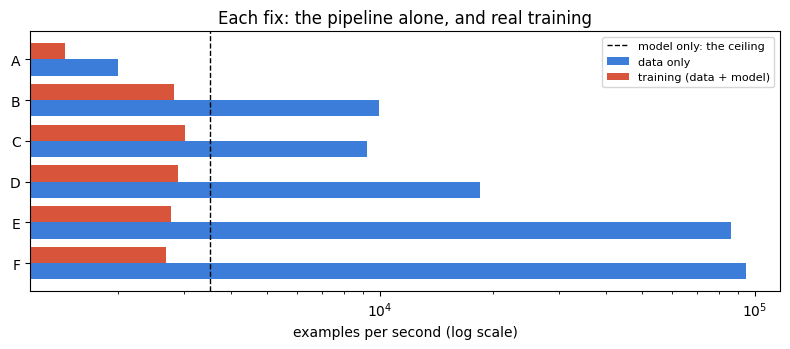

In [11]:
data_only = dict(zip(pipes, [rate["data"], b_rate, c_rate, d_rate, e_rate, f_rate]))
model_ceiling = fit_rate(model, in_memory)                    # re-measured now, on the same warm model
both = {}
for name, ds in pipes.items():
    both[name] = fit_rate(model, ds, n_batches=30)

a_name = next(iter(pipes))
print(f"{'pipeline':40s}{'data only':>11s}{'training':>10s}{'x A':>6s}")
for name in pipes:
    print(f"{name:40s}{data_only[name]:11,.0f}{both[name]:10,.0f}{both[name] / both[a_name]:6.1f}")
print(f"{'model only (one batch held in memory)':40s}{'':11s}{model_ceiling:10,.0f}")
print("\ndata-only speed, F against A : %.0f times" % (data_only[list(pipes)[-1]] / data_only[a_name]))
print("training speed,  F against A : %.1f times" % (both[list(pipes)[-1]] / both[a_name]))

fig, ax = plt.subplots(figsize=(8, 3.6))
ypos = np.arange(len(pipes))
ax.barh(ypos + 0.2, [data_only[n] for n in pipes], height=0.4, color="#3b7dd8", label="data only")
ax.barh(ypos - 0.2, [both[n] for n in pipes], height=0.4, color="#d8543b", label="training (data + model)")
ax.axvline(model_ceiling, color="k", ls="--", lw=1, label="model only: the ceiling")
ax.set_xscale("log"); ax.set_yticks(ypos); ax.set_yticklabels([n[:1] for n in pipes]); ax.invert_yaxis()
ax.set_xlabel("examples per second (log scale)"); ax.set_title("Each fix: the pipeline alone, and real training")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Why we see this

Read the two columns against each other.

- The **first** fix (A to B) took the pipeline from slower than the model to several times faster than the
  model, and training sped up by about a factor of two in the saved run.
- Every fix after that made the pipeline faster still, tens of times faster than A by the end, and **training
  barely moved**. From B onwards the model is the slow part, and no amount of work on the pipeline can push
  training past the "model only" ceiling.

That is the rule the chapter is built on: **speeding up the part that is not the bottleneck buys nothing**.
Once the bottleneck moves, stop, and go and work on the new one.

One caution about scale. On this CPU the model manages only a few thousand images a second, so pipeline B is
already enough. A GPU would run this small model many times faster, the ceiling would move far to the right,
and versions C to F would start to matter again. Which fix pays depends on the hardware, which is why you
measure on the machine you will train on.

---
## Step 12 - Throughput against batch size

Now the model side. We train on a batch held in memory at batch sizes from 1 to 512 and record examples per
second. No pipeline is involved.

> **Predict:** sketch the curve of examples per second against batch size. Does doubling the batch double the
> throughput? Everywhere?

 batch  ms per step  examples/s


     1         3.24         308


     2         3.69         542


     4         4.72         847


     8         4.72       1,696


    16         6.54       2,446


    32        11.34       2,821


    64        21.15       3,026


   128        40.47       3,163


   256        79.63       3,215


   512       145.76       3,513

batch 64 against batch 1  : 9.8 times the throughput
batch 512 against batch 64: 1.16 times the throughput


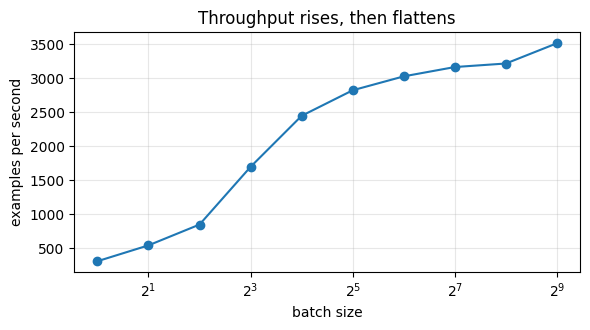

In [12]:
x_big = tf.random.uniform((512, 32, 32, 3))
y_big = tf.random.uniform((512,), 0, 10, tf.int32)
sweep_model = compiled(build_cnn())
sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
sweep = {}
print(f"{'batch':>6s}{'ms per step':>13s}{'examples/s':>12s}")
for bs in sizes:
    a, b = x_big[:bs], y_big[:bs]
    for _ in range(3):
        sweep_model.train_on_batch(a, b)                       # warm-up at this batch size
    times, t0 = [], time.perf_counter()
    while len(times) < 5 or time.perf_counter() - t0 < 1.2:
        t = time.perf_counter(); sweep_model.train_on_batch(a, b); times.append(time.perf_counter() - t)
    step = float(np.median(times))
    sweep[bs] = bs / step
    print(f"{bs:6d}{1000 * step:13.2f}{sweep[bs]:12,.0f}")
print("\nbatch 64 against batch 1  : %.1f times the throughput" % (sweep[64] / sweep[1]))
print("batch 512 against batch 64: %.2f times the throughput" % (sweep[512] / sweep[64]))

plt.figure(figsize=(6, 3.4))
plt.plot(sizes, [sweep[s] for s in sizes], "o-")
plt.xscale("log", base=2); plt.xlabel("batch size"); plt.ylabel("examples per second")
plt.title("Throughput rises, then flattens"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Why we see this

Every training step has a **fixed cost** that does not depend on the batch: entering the graph, dispatching
each operation, the optimiser's update of every weight. At batch 1 that fixed cost is nearly the whole step,
so adding examples is almost free and throughput climbs steeply. Once the arithmetic on the examples
dominates, a batch twice as big takes about twice as long, and the curve flattens.

On a GPU the same shape appears, usually with a later and higher plateau, because a large batch is what
keeps thousands of cores busy at once. It ends when memory runs out (Step 14).

Do not read this plot as "use the biggest batch". It measures examples per second, not learning per second.
Step 19 returns to that.

---
## Step 13 - Two switches in `compile`: measure them, do not trust them

- `steps_per_execution=N` runs N training steps inside one graph call, so Python is visited once every N
  steps instead of every step.
- `jit_compile=True` asks the XLA compiler to fuse the step's operations into specialised machine code.

Both are sold as speed-ups. Whether they are depends on the model and the hardware. We test
`steps_per_execution` on two models: our CNN at batch 64, and a tiny dense model at batch 8 whose step is
very short.

> **Predict:** for which of the two models will `steps_per_execution=32` help more? And will `jit_compile`
> make the CNN faster on a CPU?

In [13]:
def tiny_mlp():
    return keras.Sequential([layers.Input(shape=(32, 32, 3)), layers.Flatten(),
                             layers.Dense(32, activation="relu"), layers.Dense(10)], name="tiny")

small_batch = tf.data.Dataset.from_tensors((xb[:8], yb[:8])).repeat()

print("steps_per_execution    CNN, batch 64     tiny MLP, batch 8")
spe = {}
for n in (1, 8, 32):
    cnn_n = compiled(build_cnn(), steps_per_execution=n)
    mlp_n = compiled(tiny_mlp(), steps_per_execution=n)
    spe[n] = (fit_rate(cnn_n, in_memory, n_batches=64), fit_rate(mlp_n, small_batch, n_batches=320, batch=8))
    print(f"{n:12d}{spe[n][0]:18,.0f}{spe[n][1]:20,.0f}   examples/s")
print("gain from 1 to 32:   CNN %.2f times     tiny MLP %.2f times" % (spe[32][0] / spe[1][0], spe[32][1] / spe[1][1]))

print("\njit_compile on the CNN, batch 64")
try:
    jit_model = compiled(build_cnn(), jit_compile=True)
    t = time.perf_counter(); jit_model.fit(in_memory.take(4), epochs=1, verbose=0); jit_first = time.perf_counter() - t
    jit_rate = fit_rate(jit_model, in_memory, n_batches=30)
    print("  first call (includes compiling): %.1f s" % jit_first)
    print("  jit_compile=False: %6.0f examples/s" % spe[1][0])
    print("  jit_compile=True : %6.0f examples/s   (%.2f times)" % (jit_rate, jit_rate / spe[1][0]))
except Exception as e:                                           # some installs cannot compile with XLA
    jit_rate = None
    print("  jit_compile=True failed on this install:", type(e).__name__, str(e)[:200])

steps_per_execution    CNN, batch 64     tiny MLP, batch 8


           1             3,112               6,220   examples/s


           8             3,403              11,596   examples/s


          32             3,624              13,648   examples/s
gain from 1 to 32:   CNN 1.16 times     tiny MLP 2.19 times

jit_compile on the CNN, batch 64


  first call (includes compiling): 1.9 s
  jit_compile=False:   3112 examples/s
  jit_compile=True :    993 examples/s   (0.32 times)


### Why we see this

**`steps_per_execution`** removes the trip back to Python between steps. For the CNN that trip is a small
part of a step that is busy with convolutions, so the gain is small or lost in the noise. For the tiny model
at batch 8 the trip **is** most of the step, and the gain is large (close to a factor of two in the saved
run). The rule: it helps when steps are short. The price is that callbacks and the progress bar only see
every N-th step.

**`jit_compile`** on this CPU made the CNN **slower** in the saved run, by a wide margin, and the first call
took seconds longer because of the compilation. TensorFlow's ordinary CPU convolutions are already tuned
library routines, and the compiled replacement was not better here. On GPUs, and for models made of many
small operations, XLA often does help. The honest summary is the one this lab was built to teach: a switch
that promises speed is a hypothesis. Measure it on your model and your machine, and keep it only if it wins.

---
## Step 14 - Memory by hand

Time was the first budget. Memory is the second. During training, four groups of numbers have to be held:

1. the **parameters**,
2. one **gradient** per parameter,
3. the **optimiser's state** (Adam keeps two extra numbers per parameter: Chapter 8),
4. the **activations**: every layer's output for every example in the batch, kept because the backward pass
   needs them (Chapter 7).

Only the fourth grows with the batch size. Each number is a float32: 4 bytes.

> **Predict:** at batch 64, which of the four is the biggest? What share of the total? And at what batch size
> do the activations overtake the other three together?

In [14]:
MB = 1e6                                                          # megabytes as 10^6 bytes
per_example = {}                                                  # numbers stored per example, per layer
for layer in model.layers:
    if layer.name != "flatten":                                   # Flatten only reshapes: no new numbers
        per_example[layer.name] = int(np.prod(layer.output.shape[1:]))
hand_acts = {"conv1": 32 * 32 * 32, "conv2": 32 * 32 * 32, "pool1": 16 * 16 * 32,
             "conv3": 16 * 16 * 64, "pool2": 8 * 8 * 64, "dense": 64, "logits": 10}
assert per_example == hand_acts
A = sum(hand_acts.values())                                       # activation numbers per example

print(f"{'layer':8s}{'output shape':>16s}{'numbers/example':>18s}{'MB at batch 64':>16s}")
for layer in model.layers:
    if layer.name in hand_acts:
        n = hand_acts[layer.name]
        print(f"{layer.name:8s}{str(tuple(layer.output.shape[1:])):>16s}{n:18,}{n * 64 * 4 / MB:16.2f}")
print(f"{'sum':8s}{'':16s}{A:18,}{A * 64 * 4 / MB:16.2f}")

# what the model itself reports
probe = keras.Model(model.inputs, [model.get_layer(n).output for n in hand_acts])
measured = sum(o.numpy().nbytes for o in probe(xb))               # run one real batch of 64 and add up the bytes
assert measured == A * 64 * 4
opt_numbers = sum(int(np.prod(v.shape)) for v in model.optimizer.variables)
assert opt_numbers == 2 * P + 2                                   # Adam: two per parameter, plus a step counter and the learning rate

def training_mb(batch):
    return {"parameters": P * 4 / MB, "gradients": P * 4 / MB, "Adam state": 2 * P * 4 / MB,
            "activations": A * batch * 4 / MB}
mem = training_mb(64)
total = sum(mem.values())
print("\ntraining at batch 64, by hand:")
for k, v in mem.items():
    print(f"  {k:12s}{v:7.2f} MB   {100 * v / total:5.1f}%")
print(f"  {'total':12s}{total:7.2f} MB")
print("activation bytes measured by running a batch:", f"{measured:,}", "= the hand count")
print("optimiser numbers reported by Keras:", f"{opt_numbers:,}", "= 2 x parameters + 2")
print(f"Keras prints the parameters as {P * 4 / 1024**2:.2f} MB: it divides by 1024 x 1024, "
      f"we divide by 10^6 ({P * 4 / MB:.2f} MB)")
print("activations overtake the other three together from batch", int(np.ceil(4 * P / A)))
print(f"inference at batch 1: parameters {P * 4 / MB:.2f} MB + the two largest neighbouring "
      f"activations {2 * 32768 * 4 / MB:.2f} MB")

layer       output shape   numbers/example  MB at batch 64
conv1       (32, 32, 32)            32,768            8.39
conv2       (32, 32, 32)            32,768            8.39
pool1       (16, 16, 32)             8,192            2.10
conv3       (16, 16, 64)            16,384            4.19
pool2         (8, 8, 64)             4,096            1.05
dense              (64,)                64            0.02
logits             (10,)                10            0.00
sum                                 94,282           24.14

training at batch 64, by hand:
  parameters     1.17 MB     4.0%
  gradients      1.17 MB     4.0%
  Adam state     2.33 MB     8.1%
  activations   24.14 MB    83.8%
  total         28.80 MB
activation bytes measured by running a batch: 24,136,192 = the hand count
optimiser numbers reported by Keras: 582,998 = 2 x parameters + 2
Keras prints the parameters as 1.11 MB: it divides by 1024 x 1024, we divide by 10^6 (1.17 MB)
activations overtake the other three toge

### Why we see this

At batch 64 the activations are more than four fifths of the total, and they come almost entirely from the
two early convolutions: the layers with **few parameters and big feature maps**. The Dense layer that holds
nine tenths of the parameters contributes 64 numbers per example. Chapter 14's sentence, "the Dense layers
hold the parameters, the early convolutions do the work", has a memory version: **the early convolutions also
hold the activations**.

Three honest limits of this estimate:

- It is a **floor**. A real framework also holds the input batch, temporary workspace for the convolutions,
  and gradients of the activations during the backward pass. Expect real use to be a small multiple of it.
- It counts each layer's output once. Some layers need extra bookkeeping (max pooling must remember which
  pixel won).
- Inference keeps none of this: once a layer's output has been used it can be thrown away. That is why a
  model that cannot be trained on a device can often still be run on it.

---
## Step 15 - The same arithmetic for one transformer block

No model is built here: this cell is pure counting, for one block of GPT-2 small (2019): width 768, 12 heads,
feed-forward width 3,072, at its full context of 1,024 tokens. Chapter 23 drew the block.

Two kinds of activation live in it: tensors with one vector per token (they grow in step with the sequence
length T), and the **attention maps**, one T x T grid per head (they grow with T squared).

> **Predict:** which is larger for one example at T = 1,024: the block's 7,087,872 parameters, or one
> attention map (12 heads x 1,024 x 1,024 numbers)?

In [15]:
d, heads, ff, T = 768, 12, 3072, 1024
block_params = (4 * d * d + 4 * d) + (2 * d * ff + ff + d) + 4 * d       # attention + feed-forward + two LayerNorms
assert block_params == 7_087_872
token_tensor = T * d                                                     # one width-768 tensor
ff_hidden = T * ff                                                       # the feed-forward's wide middle
attn_map = heads * T * T                                                 # attention weights for one example
print(f"parameters in one block           : {block_params:>12,}")
print(f"one width-768 tensor, T = 1,024   : {token_tensor:>12,}   numbers per example")
print(f"feed-forward hidden layer         : {ff_hidden:>12,}   = {ff_hidden // token_tensor} such tensors")
print(f"one attention map (12 heads)      : {attn_map:>12,}   = {attn_map // token_tensor} such tensors")
print(f"                                    {attn_map * 4 / MB:12.1f}   MB per example, per block, in float32")
print(f"across 12 blocks, batch of 8      : {attn_map * 4 * 12 * 8 / 1e9:12.2f}   GB for the attention maps alone")
print()
for t in (256, 512, 1024, 2048):
    print(f"T = {t:5d}: per-token tensor {t * d:>10,}   attention map {heads * t * t:>11,}   ratio {heads * t * t / (t * d):5.1f}")

parameters in one block           :    7,087,872
one width-768 tensor, T = 1,024   :      786,432   numbers per example
feed-forward hidden layer         :    3,145,728   = 4 such tensors
one attention map (12 heads)      :   12,582,912   = 16 such tensors
                                            50.3   MB per example, per block, in float32
across 12 blocks, batch of 8      :         4.83   GB for the attention maps alone

T =   256: per-token tensor    196,608   attention map     786,432   ratio   4.0
T =   512: per-token tensor    393,216   attention map   3,145,728   ratio   8.0
T =  1024: per-token tensor    786,432   attention map  12,582,912   ratio  16.0
T =  2048: per-token tensor  1,572,864   attention map  50,331,648   ratio  32.0


### Why we see this

One attention map for one example is larger than the block's entire set of parameters, and it is the size of
16 of the block's ordinary tensors. Double the sequence length and the per-token tensors double while the
attention map quadruples. This is why long contexts run out of memory before they run out of patience, and
why Chapter 25's implementations that never store the full map (flash attention) matter so much.

These are counts of the largest items, not a full audit: a real implementation stores several per-token
tensors per block, and a memory-efficient attention kernel may never hold the T x T map at all.

---
## Step 16 - Gradient accumulation: a big batch in small pieces

Suppose batch 64 does not fit in memory but batch 16 does. Run four batches of 16, **add up their gradients,
divide by four, and only then let the optimiser step**. The claim is that this is the same update as one
batch of 64, because the gradient of a mean is the mean of the gradients.

We do not take that on trust. The cell computes both and compares every one of the 291,498 numbers.

> **Predict:** will the two gradients agree exactly, to about 6 decimal places, or only roughly? And what
> happens if you forget to divide by four?

In [16]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)   # the MEAN loss over the batch

def gradients(net, x, y):
    with tf.GradientTape() as tape:
        loss = loss_fn(y, net(x, training=True))
    return tape.gradient(loss, net.trainable_variables)

def flat(grads):
    return np.concatenate([g.numpy().ravel() for g in grads])

acc_model = build_cnn()                                    # fresh weights; the comparison holds for any weights
g_big = gradients(acc_model, xb, yb)                       # one batch of 64

g_sum = [tf.zeros_like(v) for v in acc_model.trainable_variables]
for k in range(4):                                         # four batches of 16: the same 64 images
    g_part = gradients(acc_model, xb[16 * k:16 * k + 16], yb[16 * k:16 * k + 16])
    g_sum = [s + g for s, g in zip(g_sum, g_part)]
g_acc = [s / 4.0 for s in g_sum]                           # the average of the four

big, acc, forgot = flat(g_big), flat(g_acc), flat(g_sum)
print("numbers compared               :", f"{big.size:,}")
print("largest gradient entry         : %.6f" % np.abs(big).max())
print("largest difference             : %.2e" % np.abs(big - acc).max())
print("relative difference of the two : %.2e" % (np.linalg.norm(big - acc) / np.linalg.norm(big)))
assert np.allclose(big, acc, rtol=1e-4, atol=1e-6), "accumulated gradient differs from the big-batch gradient"
print("PASS: four batches of 16, averaged, give the gradient of one batch of 64")
print("forgot to divide: gradient is %.2f times too large" % (np.linalg.norm(forgot) / np.linalg.norm(big)))

# one optimiser step each way, from the same starting weights
w0 = acc_model.get_weights()
def one_step(grads):
    net = build_cnn(); net.set_weights(w0)
    keras.optimizers.SGD(0.1).apply_gradients(zip(grads, net.trainable_variables))
    return np.concatenate([w.ravel() for w in net.get_weights()])
w_big, w_acc = one_step(g_big), one_step(g_acc)
print("largest weight difference after one SGD step: %.2e" % np.abs(w_big - w_acc).max())
assert np.allclose(w_big, w_acc, rtol=1e-5, atol=1e-6)

numbers compared               : 291,498
largest gradient entry         : 0.099416
largest difference             : 5.77e-08
relative difference of the two : 5.68e-07
PASS: four batches of 16, averaged, give the gradient of one batch of 64
forgot to divide: gradient is 4.00 times too large
largest weight difference after one SGD step: 2.98e-08


### Why we see this

The two gradients agree to within float32 rounding: adding numbers in a different order changes the last
digit or two and nothing else. So the update is the same, and the memory needed at any moment is that of
batch 16: about a quarter of the activations.

What accumulation does **not** give you:

- **Speed.** It is four forward and backward passes. Wall-clock time per update is that of four small steps
  (and from Step 12 you know small batches use the hardware less well).
- **A free pass on the learning rate.** The effective batch is 64, so the learning rate that suits batch 64
  is the right one (Chapter 8).
- If the last pieces have different sizes, weight each gradient by its number of examples, or the small
  piece counts for too much.

---
## Step 17 - The catch: BatchNorm sees the small batches

The proof above used "the gradient of a mean is the mean of the gradients". That needs each example's loss to
depend only on that example. **Batch normalisation breaks it** (Chapter 10): in training mode it normalises
each example using the mean and variance of **the batch it arrived in**. A batch of 16 has different
statistics from the batch of 64 that contains it.

> **Predict:** add BatchNorm after each convolution and repeat Step 16. Same gradient, or not? If not, off by
> a rounding error or by something you would notice?

In [17]:
def build_cnn_bn():
    return keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.ReLU(),
        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.ReLU(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same"), layers.BatchNormalization(), layers.ReLU(),
        layers.MaxPooling2D(), layers.Flatten(),
        layers.Dense(64, activation="relu"), layers.Dense(10),
    ], name="cnn_bn")

bn_model = build_cnn_bn()
gb = flat(gradients(bn_model, xb, yb))
parts = [flat(gradients(bn_model, xb[16 * k:16 * k + 16], yb[16 * k:16 * k + 16])) for k in range(4)]
ga = np.mean(parts, axis=0)
rel_plain = np.linalg.norm(big - acc) / np.linalg.norm(big)
rel_bn = np.linalg.norm(gb - ga) / np.linalg.norm(gb)
cos = float(gb @ ga / (np.linalg.norm(gb) * np.linalg.norm(ga)))
print("relative difference, plain CNN     : %.2e   (rounding)" % rel_plain)
print("relative difference, with BatchNorm: %.2e   (%.0f%% of the gradient's length)" % (rel_bn, 100 * rel_bn))
print("cosine between the two BatchNorm gradients: %.3f" % cos)
assert rel_bn > 100 * rel_plain

relative difference, plain CNN     : 5.68e-07   (rounding)
relative difference, with BatchNorm: 3.79e-01   (38% of the gradient's length)
cosine between the two BatchNorm gradients: 0.927


### Why we see this

With BatchNorm the accumulated gradient is a different gradient: not a rounding error apart but visibly
apart. It still points in a broadly similar direction, so training usually works, but it is the training of
a model normalised over 16 examples, with the noisier statistics that implies. If the reason you are
accumulating is that only 2 or 4 examples fit, BatchNorm's statistics become unreliable, and a normaliser
that does not look across the batch (LayerNorm or GroupNorm, Chapter 10) is the cure.

---
## Step 18 - Mixed precision: what it changes, and what it needs

**Mixed precision** computes the forward and backward pass in 16-bit floats and keeps the weights in 32-bit.
The cell first shows three facts about float16 that explain the design, then switches the policy on, builds
the CNN again and inspects it.

> **Predict:** a float16 has about 3 significant decimal digits. What is `1 + 0.0001` in float16? What does
> that say about storing the **weights** in float16 when a typical update is a tiny fraction of the weight?

> **About speed, read this before the cell:** mixed precision is fast on GPUs whose hardware has dedicated
> 16-bit arithmetic. **This lab runs on a CPU, which has no such thing**, so the cell times two steps only to
> show you what happens here. It is not a measurement of what mixed precision does on a GPU, and the chapter
> claims no speed-up from it.

In [18]:
h = np.float16
print("float16: 1 + 0.0001        =", h(1) + h(0.0001), "  (the small update vanished)")
print("float16: smallest step at 1 =", np.finfo(h).eps, " | float32:", np.finfo(np.float32).eps)
print("float16: 1e-8 stored as     =", h(1e-8), "  (a small gradient underflows to zero)")
print("float16: largest value      =", np.finfo(h).max, " | exp(12) =", float(np.exp(np.float32(12))), "would overflow")

keras.mixed_precision.set_global_policy("mixed_float16")
try:
    mp_model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(name="pool1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv3"),
        layers.MaxPooling2D(name="pool2"),
        layers.Flatten(name="flatten"),
        layers.Dense(64, activation="relu", name="dense"),
        layers.Dense(10, dtype="float32", name="logits"),          # the output layer stays in float32
    ], name="cnn_mixed")
    compiled(mp_model)
    print("\nlayer    computes in   stores weights in")
    for name in ("conv1", "dense", "logits"):
        layer = mp_model.get_layer(name)
        print(f"{name:8s} {layer.compute_dtype:12s}  {layer.variable_dtype}")
    print("optimiser wrapper:", type(mp_model.optimizer).__name__)
    mp_probe = keras.Model(mp_model.inputs, [mp_model.get_layer(n).output for n in hand_acts])
    mp_bytes = sum(o.numpy().nbytes for o in mp_probe(xb))
    print(f"activation bytes at batch 64: float32 {measured:,} | mixed {mp_bytes:,} "
          f"| ratio {mp_bytes / measured:.3f}")
    assert mp_model.count_params() == P                               # same model, same parameter count
    mp_model.fit(in_memory.take(2), epochs=1, verbose=0)              # warm-up
    t = time.perf_counter(); mp_model.fit(in_memory.take(2), epochs=1, verbose=0)
    mp_rate = 2 * BATCH / (time.perf_counter() - t)
    print(f"on THIS CPU: mixed precision {mp_rate:.0f} examples/s against {model_ceiling:.0f} "
          f"in float32 ({model_ceiling / mp_rate:.0f} times slower)")
finally:
    keras.mixed_precision.set_global_policy("float32")               # always put the default back
print("policy restored to:", keras.mixed_precision.global_policy().name)

float16: 1 + 0.0001        = 1.0   (the small update vanished)
float16: smallest step at 1 = 0.000977  | float32: 1.1920929e-07
float16: 1e-8 stored as     = 0.0   (a small gradient underflows to zero)
float16: largest value      = 6.55e+04  | exp(12) = 162754.78125 would overflow

layer    computes in   stores weights in
conv1    float16       float32
dense    float16       float32
logits   float32       float32
optimiser wrapper: LossScaleOptimizer
activation bytes at batch 64: float32 24,136,192 | mixed 12,069,376 | ratio 0.500


on THIS CPU: mixed precision 26 examples/s against 3517 in float32 (137 times slower)
policy restored to: float32


### Why we see this

- `1 + 0.0001` is still `1` in float16. A weight stored in float16 could not absorb a small update, so the
  **weights stay in float32** and only the computation drops to 16 bits. That is the "mixed" in the name.
- A gradient of `1e-8` becomes exactly zero in float16. The cure is **loss scaling**: multiply the loss by a
  large factor before the backward pass so that small gradients stay representable, and divide the gradients
  by the same factor before the update. Keras wraps your optimiser in a `LossScaleOptimizer` to do this, as
  the printout shows.
- The **output layer stays in float32** (`dtype="float32"`), because a softmax and a cross-entropy over many
  classes are where 16 bits overflow or lose their small probabilities.
- The activation memory fell to about half: that is the saving that lets a larger batch fit.

And the speed on this machine: far slower, not faster. A CPU has no fast float16 arithmetic, so every
operation takes a slow path. On a GPU with 16-bit hardware support the same switch usually speeds training
up as well as halving the activation memory, but that is a statement about that hardware, and this lab did
not measure it. If you have such a GPU, measuring it is Exercise 5.

---
## Step 19 - Throughput is not the goal: time to a result

Step 12 said that large batches process more examples per second. It is tempting to conclude that the
largest batch trains fastest. The thing you want is not examples per second. It is **a model that reaches a
given accuracy, as soon as possible**.

We train the same CNN three times from the same starting weights with batch 16, 64 and 512, the learning rate
left at 0.001 each time, and stop each run after about 12 seconds of training. After every epoch we note the
training time used so far and the validation accuracy. (Decoded images held in memory, no augmentation, to
keep the comparison about the batch size alone.)

> **Predict:** which batch size will have the highest examples per second? Which will have the highest
> validation accuracy when the 12 seconds are up?

 batch  examples/s  updates  final val acc  time to 45%
    16       1,826    1,500          0.491        9.1 s
    64       2,459      500          0.533        7.0 s
   512       2,622       64          0.426  not reached


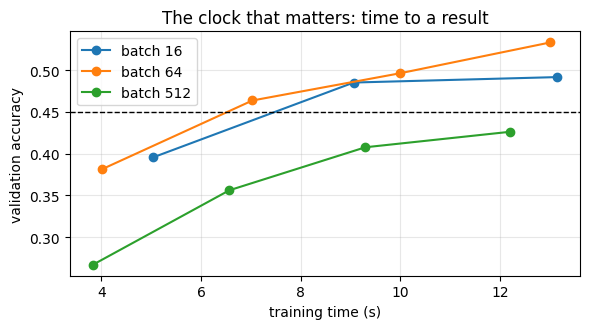


whole notebook: 135 seconds


In [19]:
x_train = x_raw[:N_TRAIN].astype("float32") / 255.0
BUDGET, TARGET = 12.0, 0.45
runs = {}
for bs in (16, 64, 512):
    keras.utils.set_random_seed(SEED)                              # the same starting weights each time
    net = compiled(build_cnn())
    used, hist = 0.0, []
    while used < BUDGET:
        t = time.perf_counter()
        net.fit(x_train, y_train, batch_size=bs, epochs=1, shuffle=True, verbose=0)
        used += time.perf_counter() - t
        acc_val = net.evaluate(x_val, y_val, batch_size=500, verbose=0)[1]   # not counted in the budget
        hist.append((used, acc_val))
    runs[bs] = hist

print(f"{'batch':>6s}{'examples/s':>12s}{'updates':>9s}{'final val acc':>15s}{'time to %d%%' % (100 * TARGET):>13s}")
for bs, hist in runs.items():
    epochs = len(hist)
    reached = next((f"{t:.1f} s" for t, a in hist if a >= TARGET), "not reached")
    print(f"{bs:6d}{epochs * N_TRAIN / hist[-1][0]:12,.0f}{epochs * int(np.ceil(N_TRAIN / bs)):9,}"
          f"{hist[-1][1]:15.3f}{reached:>13s}")

plt.figure(figsize=(6, 3.4))
for bs, hist in runs.items():
    plt.plot([t for t, _ in hist], [a for _, a in hist], "o-", label=f"batch {bs}")
plt.axhline(TARGET, color="k", ls="--", lw=1)
plt.xlabel("training time (s)"); plt.ylabel("validation accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("The clock that matters: time to a result"); plt.tight_layout(); plt.show()

print("\nwhole notebook: %.0f seconds" % (time.time() - t_start))

### Why we see this

The largest batch wins on examples per second and, in the saved run, loses on the thing you wanted: in the
same training time it made far fewer weight updates, and with the learning rate left unchanged each of those
updates was no bigger. A big batch gives a less noisy gradient and so can afford a larger learning rate
(Chapter 8); if you do not raise it, you paid for precision you did not use. The smallest batch made the most
updates but ran well below the hardware's best throughput.

This is a short run of a small model on a small subset, and the ranking can change with a tuned learning
rate, a longer budget or different hardware. The habit is what transfers: **compare settings by time to a
target accuracy on your validation set**, not by seconds per epoch and not by examples per second.

---
## Trials: change one thing at a time

Write your prediction first, then run, then fill in what you observed.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | In Step 4, drop the brightness shift from `clumsy_one` | Does pipeline A get much faster? Which line of it is really the slow one? | |
| 2 | In Step 7, add `num_parallel_calls=AUTO` to both `map` calls of pipeline B | How does it compare with D, which vectorised first? | |
| 3 | In Step 9, move `.shuffle(N_TRAIN)` to **after** `.batch(BATCH)` | Speed? And what is now wrong with the batches from epoch to epoch? | |
| 4 | In Step 11, swap the CNN for `tiny_mlp()` | Now which pipelines limit training? Where does the bottleneck move? | |
| 5 | In Step 12, replace the CNN with `tiny_mlp()` in the sweep | Where does the curve flatten now? Earlier or later? | |
| 6 | In Step 14, change the first two convolutions to 64 filters | New activation total? New share at batch 64? | |
| 7 | In Step 16, use 8 pieces of 8 instead of 4 of 16 | Does the assert still pass? Is the difference larger? | |
| 8 | In Step 19, give batch 512 a learning rate of 0.004 | Does it reach the target now? Sooner than batch 64? | |

## Exercises

1. **A profile as a pie.** Using the Step 6 method, produce a three-slice breakdown of one training step for
   pipeline A: decode, augment, model. (Hint: time a version of `clumsy_one` that only decodes.)
2. **The accumulation loop.** Write a custom training loop that trains the CNN with batches of 16 and an
   optimiser step every 4 batches. Check that after one update its weights match one step of batch 64.
3. **Print in the hot loop.** Write a loop of `train_on_batch` calls on the tiny MLP at batch 8. Time it with
   and without `print(float(loss))` on every step. What does the print cost as a share of the step?
4. **A shuffle buffer that is too small.** Sort the training files by label, then build a pipeline with
   `shuffle(64)`. Print the class counts of the first five batches. What will the model learn from them?
5. **If you have a GPU.** Run Steps 6, 11, 12, 13 and 18 again on it. Which conclusions of this lab survive
   unchanged, and which reverse? Write down the numbers and the date.
6. **Cost.** Suppose a machine costs 1 unit of currency per hour. Using your Step 19 numbers, what did it
   cost to reach the target with each batch size? Which column of the table would you report to a manager?

## Cheat sheet

| Idea | One line |
|---|---|
| First rule | Measure before you change anything: data only, model only, both |
| Fair timing | Warm up, repeat, take the median, quote examples per second |
| The two bottlenecks | The pipeline cannot feed the model fast enough, or the model and batch do not fit in memory |
| `tf.data` order | `map(decode)` -> `cache` -> `shuffle` -> `batch` -> `map(augment)` -> `prefetch` |
| `cache` | After the work that never changes, before anything random; only if it fits in memory |
| Vectorise | One call on a batch beats 64 calls on single images |
| `prefetch` | Last in the pipeline: prepares batches while the model trains |
| Bottleneck rule | Speeding up the part that is not the bottleneck buys nothing |
| Batch size | Throughput rises with the batch, then flattens; memory rises in a straight line |
| `steps_per_execution` | Helps when steps are short; measure it |
| `jit_compile` | May help or hurt; measure it |
| Training memory | parameters + gradients + optimiser state + activations x batch |
| Gradient accumulation | Average the gradients of k small batches, then step: the big-batch update at small-batch memory, not faster |
| Its catch | BatchNorm sees the small batch, so the gradient is not the same |
| Mixed precision | Compute in float16, keep weights and the output layer in float32; needs a GPU with 16-bit support to be fast |
| The real metric | Time (and money) to a target validation accuracy |